# Деревья решений

# Цели обучения

- Распознавание деревьев решений и их применение к задачам классификации.
- Определение наилучшего разбиения и признаков для разбиения.
- Анализ сильных и слабых сторон деревьев решений.
- Рассмотрение того, как деревья регрессии позволяют предсказывать непрерывные значения.
- Применение расширения Intel® для Scikit-learn* для использования вычислительных возможностей аппаратного обеспечения.

## Введение

В работе используется набор данных о качестве вина (`Wine_Quality_Data.csv`). Он содержит химические свойства вина (кислотность, содержание сахара, pH, содержание алкоголя и др.), оценку качества (от 3 до 9, где более высокий балл означает лучшее качество) и цвет вина (красное или белое).

Дерево решений используется для двух задач: классификации (определение цвета вина) и регрессии (предсказание содержания остаточного сахара).

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz, plot_tree
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('scikit-learn-intelex не установлен — используется стандартный scikit-learn')

%matplotlib inline

scikit-learn-intelex не установлен — используется стандартный scikit-learn


## Вопрос 1. Импорт и изучение данных

На данном этапе выполняется:

- импорт данных и изучение признаков;
- подготовка целевой переменной: все признаки используются для предсказания `color` (белое или красное вино), однако признак цвета должен быть закодирован целым числом.

In [2]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data - Wine_Quality_Data.csv'])
data = pd.read_csv(filepath)
print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

In [4]:
data.describe().T[['count', 'mean', 'std', 'min', 'max']]

,count,mean,std,min,max
fixed_acidity,6497.0,7.215307,1.296434,3.80000,15.9000
volatile_acidity,6497.0,0.339666,0.164636,0.08000,1.5800
citric_acid,6497.0,0.318633,0.145318,0.00000,1.6600
residual_sugar,6497.0,5.443235,4.757804,0.60000,65.8000
chlorides,6497.0,0.056034,0.035034,0.00900,0.6110
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,289.0000
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,440.0000
density,6497.0,0.997650,0.025023,0.98711,1.2026
pH,6497.0,3.218501,0.160787,2.72000,4.0100
sulphates,6497.0,0.531268,0.148806,0.22000,2.0000


Преобразование признака цвета в целое число (быстрый способ средствами Pandas): красное вино → 1, белое → 0.

In [5]:
data['color'] = data.color.map({'red': 1, 'white': 0}).astype(int)
data.color.value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

### Выводы к вопросу 1

* Набор содержит 6 497 записей и 13 столбцов: 11 вещественных химических признаков, целочисленное `quality` и текстовый `color`.
* Признаки имеют сильно различающиеся масштабы (например, `density` ≈ 1, `total_sulfur_dioxide` до 440, `residual_sugar` до 65,8). Для деревьев решений это не проблема: разбиение выбирается по порогу одного признака, поэтому **масштабирование не требуется** (в отличие от SVM из предыдущей работы).
* `color` — строка, а `sklearn` работает только с числами, поэтому цвет закодирован целым числом: красное → 1 (1 599 записей), белое → 0 (4 898 записей). Классы несбалансированы (≈ 25 % / 75 %), поэтому одной точности для оценки недостаточно — далее используются также precision, recall и F1.

## Вопрос 2. Разбиение на обучающую и тестовую выборки

На данном этапе выполняется:

- разбиение данных на обучающую и тестовую выборки с помощью `StratifiedShuffleSplit`, стратифицированное по качеству вина; индексы разбиения сохраняются для использования в вопросе 5;
- проверка процентной доли каждого уровня качества в обучающем и тестовом наборах.

In [6]:
feature_cols = [x for x in data.columns if x != 'color']

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(data[feature_cols], data['quality']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'color']
X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'color']
print(X_train.shape, X_test.shape)

(5197, 12) (1300, 12)


Процентная доля каждого уровня качества в исходных, обучающих и тестовых данных.

In [7]:
quality_share = pd.DataFrame({
    'всего': data.quality.value_counts(normalize=True),
    'train': data.loc[train_idx, 'quality'].value_counts(normalize=True),
    'test': data.loc[test_idx, 'quality'].value_counts(normalize=True),
}).sort_index()
(quality_share * 100).round(2)

,всего,train,test
quality,,,
3,0.46,0.46,0.46
4,3.32,3.33,3.31
5,32.91,32.90,32.92
6,43.65,43.66,43.62
7,16.61,16.61,16.62
8,2.97,2.96,3.00
9,0.08,0.08,0.08


Доля красного и белого вина (как видно, набор данных в основном состоит из белого вина).

In [8]:
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test': y_test.value_counts(normalize=True)}).rename(index={0: 'белое', 1: 'красное'}).round(4)

,train,test
color,,
белое,0.7512,0.7646
красное,0.2488,0.2354


### Выводы к вопросу 2

* Выборка разбита в пропорции 80 % / 20 % (5 197 обучающих и 1 300 тестовых записей). Стратификация выполнена **по качеству вина**, `random_state = 42` делает разбиение воспроизводимым; индексы `train_idx` и `test_idx` сохранены для вопроса 5.
* Доли всех уровней качества практически идентичны в исходных, обучающих и тестовых данных (например, качество 6: 43,65 % / 43,66 % / 43,62 %; качество 9: 0,08 % во всех трёх). Тестовая выборка поэтому репрезентативна по качеству, а редкие классы (3, 9) попали в обе части.
* Стратификация шла по `quality`, а не по цвету, поэтому доля красного вина немного отличается: 24,9 % в обучающей и 23,5 % в тестовой выборке. Различие небольшое, но объясняет часть расхождения метрик между train и test.

## Вопрос 3. Дерево решений без ограничений

На данном этапе выполняется:

- построение классификатора на основе дерева решений без ограничений на максимальную глубину, количество признаков и количество листьев;
- определение количества узлов и глубины полученного (очень большого) дерева;
- оценка погрешности прогнозирования на обучающей и тестовой выборках и анализ того, что происходит с моделью, исходя из различий в погрешности.

In [9]:
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

Количество узлов и фактическая максимальная глубина дерева.

In [10]:
print('Узлов в дереве:', dt.tree_.node_count)
print('Листьев:', dt.get_n_leaves())
print('Максимальная глубина:', dt.get_depth())

Узлов в дереве: 151
Листьев: 76
Максимальная глубина: 21


In [11]:
def measure_error(y_true, y_pred, label):
    return pd.Series({'accuracy': accuracy_score(y_true, y_pred),
                      'precision': precision_score(y_true, y_pred),
                      'recall': recall_score(y_true, y_pred),
                      'f1': f1_score(y_true, y_pred)}, name=label)

train_test_full_error = pd.concat([measure_error(y_train, dt.predict(X_train), 'train'),
                                   measure_error(y_test, dt.predict(X_test), 'test')], axis=1)
train_test_full_error.round(4)

,train,test
accuracy,0.9996,0.9854
precision,0.9992,0.9644
recall,0.9992,0.9739
f1,0.9992,0.9691


### Выводы к вопросу 3

* Дерево без ограничений имеет **151 узел** (76 листьев) и глубину **21**. Оно росло до тех пор, пока каждый лист не стал чистым, то есть дерево фактически «запомнило» обучающую выборку.
* **Погрешности.** На обучающей выборке accuracy = 0,9996, precision = recall = 0,9992 — почти идеальные значения (дерево ошибается лишь на нескольких объектах). На тестовой выборке accuracy = 0,9854, precision = 0,9644, recall = 0,9739, F1 = 0,9691.
* **Интерпретация.** Разрыв между обучением и тестом (особенно по precision и F1: 0,999 → 0,964–0,969) — признак **переобучения**: часть структуры дерева описывает шум обучающей выборки. Переобучение здесь умеренное, так как задача простая и цвета вина хорошо разделимы по химическим признакам, но тенденция очевидна: неограниченное дерево склонно подгоняться под обучающие данные.

## Вопрос 4. Подбор дерева решений с помощью поиска по сетке

На данном этапе выполняется:

- поиск по сетке с перекрёстной валидацией (`GridSearchCV`) дерева решений, которое хорошо работает на тестовом наборе. Модель сохраняется под другим именем, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6;
- определение количества узлов и глубины найденного дерева;
- расчёт погрешностей на обучающей и тестовой выборках и сравнение их с погрешностями дерева из вопроса 3.

In [12]:
param_grid = {'max_depth': range(1, dt.get_depth() + 1, 2),
              'max_features': range(1, len(feature_cols) + 1)}

GR = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid=param_grid,
                  scoring='accuracy', n_jobs=-1, cv=5)
GR = GR.fit(X_train, y_train)

print('Лучшие параметры:', GR.best_params_)
print('Средняя точность кросс-валидации:', round(GR.best_score_, 4))

Лучшие параметры: {'max_depth': 7, 'max_features': 12}
Средняя точность кросс-валидации: 0.9881


Количество узлов и максимальная глубина дерева.

In [13]:
dt_cv = GR.best_estimator_
print('Узлов в дереве:', dt_cv.tree_.node_count)
print('Листьев:', dt_cv.get_n_leaves())
print('Максимальная глубина:', dt_cv.get_depth())

Узлов в дереве: 67
Листьев: 34
Максимальная глубина: 7


In [14]:
train_test_cv_error = pd.concat([measure_error(y_train, dt_cv.predict(X_train), 'train'),
                                 measure_error(y_test, dt_cv.predict(X_test), 'test')], axis=1)

comparison = pd.concat({'без ограничений (Q3)': train_test_full_error,
                        'после GridSearchCV (Q4)': train_test_cv_error}, axis=1)
comparison.round(4)

без ограничений (Q3)         после GridSearchCV (Q4)        
                         train    test                   train    test
accuracy                0.9996  0.9854                  0.9937  0.9854
precision               0.9992  0.9644                  0.9953  0.9799
recall                  0.9992  0.9739                  0.9791  0.9575
f1                      0.9992  0.9691                  0.9871  0.9686

### Выводы к вопросу 4

* Поиск по сетке (`max_depth` — нечётные значения от 1 до 21, `max_features` — от 1 до 12, 5-кратная кросс-валидация) выбрал `max_depth = 7` и `max_features = 12` (средняя точность кросс-валидации 0,9881).
* Найденное дерево намного компактнее: **67 узлов** (34 листа) и глубина **7** против 151 узла и глубины 21 у дерева из вопроса 3.
* **Сравнение.** Точность на тесте та же (0,9854), но качество «подгонки» под обучение снизилось: accuracy на обучении 0,9996 → 0,9937. Precision на тесте выросла (0,9644 → 0,9799), recall снизился (0,9739 → 0,9575), F1 практически не изменился (0,9691 → 0,9686). Разрыв между train и test для accuracy сократился с 1,4 до 0,8 п.п.
* **Вывод:** ограничение глубины сильно упростило модель (в 2 раза меньше узлов) без потери качества на тесте — то есть переобучение дерева из вопроса 3 действительно было, но небольшим. Улучшения на тесте нет, но модель проще, устойчивее и легче интерпретируется. Практический принцип: из моделей с одинаковым качеством следует выбирать более простую.

## Вопрос 5. Дерево регрессии для остаточного сахара

На данном этапе выполняется:

- повторное разбиение данных на `X` и `y`, на этот раз с `residual_sugar` в качестве предсказываемой переменной; для разбиения повторно используются индексы, сохранённые в вопросе 2;
- поиск по сетке с перекрёстной валидацией **регрессионного** дерева решений, хорошо работающего на тестовой выборке;
- оценка погрешности на обучающей и тестовой выборках с помощью среднеквадратичной ошибки;
- построение графика фактических *и* предсказанных значений остаточного сахара.

In [15]:
feature_cols_reg = [x for x in data.columns if x != 'residual_sugar']

X_train_reg = data.loc[train_idx, feature_cols_reg]
y_train_reg = data.loc[train_idx, 'residual_sugar']
X_test_reg = data.loc[test_idx, feature_cols_reg]
y_test_reg = data.loc[test_idx, 'residual_sugar']

# Эталон: дерево без ограничений (чтобы понимать, насколько подбор параметров помогает)
dr_full = DecisionTreeRegressor(random_state=42).fit(X_train_reg, y_train_reg)
print('Без ограничений: узлов', dr_full.tree_.node_count, ', глубина', dr_full.get_depth())
print('  MSE train:', round(mean_squared_error(y_train_reg, dr_full.predict(X_train_reg)), 4),
      ' MSE test:', round(mean_squared_error(y_test_reg, dr_full.predict(X_test_reg)), 4))

param_grid_reg = {'max_depth': range(1, dr_full.get_depth() + 1, 2),
                  'max_features': range(1, len(feature_cols_reg) + 1)}

GR_reg = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid=param_grid_reg,
                      scoring='neg_mean_squared_error', n_jobs=-1, cv=5)
GR_reg = GR_reg.fit(X_train_reg, y_train_reg)
print('Лучшие параметры:', GR_reg.best_params_)

Без ограничений: узлов 7561 , глубина 28
  MSE train: 0.0001  MSE test: 2.8577


Лучшие параметры: {'max_depth': 17, 'max_features': 8}


Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

In [16]:
dr = GR_reg.best_estimator_
print('Узлов в дереве:', dr.tree_.node_count)
print('Листьев:', dr.get_n_leaves())
print('Максимальная глубина:', dr.get_depth())

Узлов в дереве: 5719
Листьев: 2860
Максимальная глубина: 17


Ошибка на обучающем и тестовом наборах. Поскольку речь идёт о непрерывных величинах, используется среднеквадратичная ошибка (MSE); для наглядности приводится также RMSE в тех же единицах, что и сахар (г/л).

In [17]:
mse_train = mean_squared_error(y_train_reg, dr.predict(X_train_reg))
mse_test = mean_squared_error(y_test_reg, dr.predict(X_test_reg))
pd.DataFrame({'MSE': [mse_train, mse_test], 'RMSE': [mse_train ** .5, mse_test ** .5]},
             index=['train', 'test']).round(4)

,MSE,RMSE
train,0.0604,0.2457
test,3.1318,1.7697


In [18]:
print('Стандартное отклонение y_test (ориентир для RMSE):', round(y_test_reg.std(), 4))
print('MSE модели «всегда предсказывать среднее»:',
      round(mean_squared_error(y_test_reg, np.full(len(y_test_reg), y_train_reg.mean())), 4))

Стандартное отклонение y_test (ориентир для RMSE): 4.6448
MSE модели «всегда предсказывать среднее»: 21.5845


График фактического и предсказанного остаточного содержания сахара.

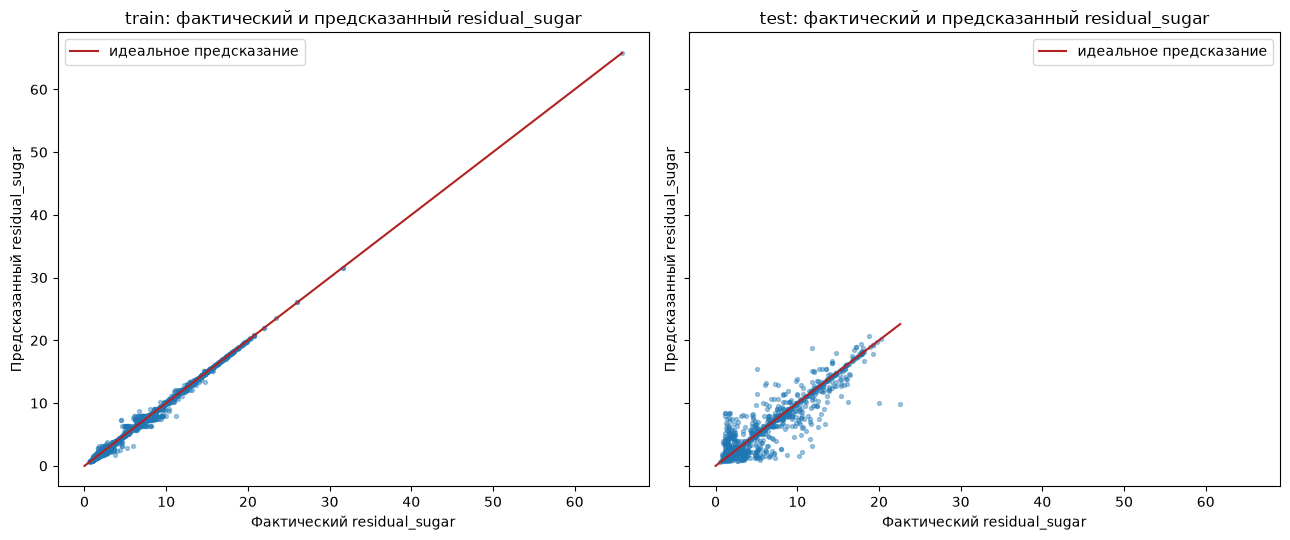

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, (Xs, ys, name) in zip(axes, [(X_train_reg, y_train_reg, 'train'), (X_test_reg, y_test_reg, 'test')]):
    ax.scatter(ys, dr.predict(Xs), s=8, alpha=.4)
    lim = [0, ys.max()]
    ax.plot(lim, lim, color='firebrick', lw=1.5, label='идеальное предсказание')
    ax.set(title=f'{name}: фактический и предсказанный residual_sugar',
           xlabel='Фактический residual_sugar', ylabel='Предсказанный residual_sugar')
    ax.legend()
plt.tight_layout()

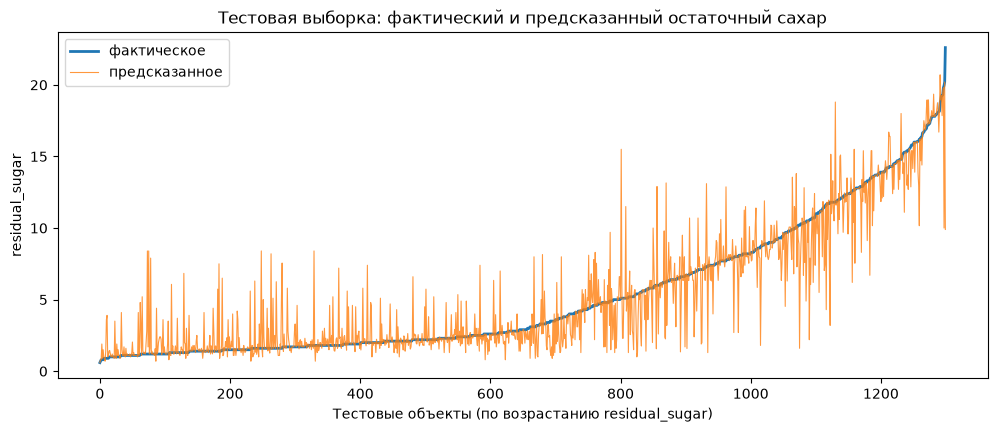

In [20]:
# Тот же результат в виде кривых: тестовые объекты упорядочены по фактическому значению
order = np.argsort(y_test_reg.values)
plt.figure(figsize=(12, 4.5))
plt.plot(y_test_reg.values[order], label='фактическое', lw=2)
plt.plot(dr.predict(X_test_reg)[order], label='предсказанное', lw=.8, alpha=.8)
plt.xlabel('Тестовые объекты (по возрастанию residual_sugar)'); plt.ylabel('residual_sugar')
plt.legend(); plt.title('Тестовая выборка: фактический и предсказанный остаточный сахар');

### Выводы к вопросу 5

* **Дерево регрессии** предсказывает значение как среднее по листу. Для `residual_sugar` поиск по сетке выбрал `max_depth = 17` и `max_features = 8`; дерево содержит 5 719 узлов (2 860 листьев). Столь большое число узлов объясняется непрерывным характером целевой переменной: чтобы точно описать множество разных значений, нужно много листьев.
* **Ошибки.** MSE на обучающей выборке — 0,060 (RMSE ≈ 0,25 г/л), на тестовой — 3,13 (RMSE ≈ 1,77 г/л). Для ориентира: стандартное отклонение сахара на тесте равно 4,64, а модель «всегда предсказывать среднее» имеет MSE ≈ 21,6. Следовательно, дерево объясняет около 85 % дисперсии (R² ≈ 0,86) и существенно лучше тривиального прогноза.
* **Переобучение выражено сильнее, чем в классификации:** разрыв train/test огромный (0,06 против 3,13). Дерево без ограничений даёт на тесте MSE = 2,86 (глубина 28, 7 561 узел) — то есть выбранное кросс-валидацией дерево на тесте не лучше. Причина: сетка по `max_depth` с шагом 2 и кросс-валидация на обучающих данных не гарантируют лучший результат на конкретной тестовой выборке, а разница (3,13 и 2,86) лежит в пределах шума.
* **График** показывает: на обучающей выборке все точки лежат на диагонали «фактическое = предсказанное» (запоминание), а на тестовой облако заметно шире. Наибольший разброс — при малых значениях сахара (до ≈ 5 г/л), где фактические значения 0–5 иногда предсказываются как 6–8; есть и отдельные крупные промахи (например, фактическое ≈ 20 г/л, предсказанное ≈ 10 г/л). Общая линейная тенденция при этом сохранена. Единственный экстремальный объект (≈ 66 г/л) попал в обучающую выборку, поэтому на тесте большие значения представлены слабо.
* Деревья регрессии дают кусочно-постоянный прогноз; для более гладких и точных результатов на практике применяют ансамбли (бэггинг, случайный лес, бустинг), которые рассматриваются в следующих работах.

## Вопрос 6 *(необязательный)*

Для визуализации деревьев с помощью GraphViz требуются дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). Если они недоступны, деревья строятся встроенной в scikit-learn функцией `plot_tree` (matplotlib), которая не требует установки дополнительных программ.

На данном этапе выполняется:

- визуализация дерева решений из вопроса 3, предсказывавшего цвет вина, без ограничения числа признаков и разбиений;
- визуализация дерева решений из вопроса 4, предсказывавшего цвет вина, для которого оптимальные глубина и число признаков найдены поиском по сетке.

Дерево из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.

In [21]:
try:
    import pydotplus
    pydotplus_installed = True
except Exception:
    print('PyDotPlus не установлен — используется plot_tree из scikit-learn.')
    pydotplus_installed = False

PyDotPlus не установлен — используется plot_tree из scikit-learn.


Дерево из вопроса 3. Оно очень большое, поэтому показаны только первые 3 уровня (полное дерево содержит сотни узлов).

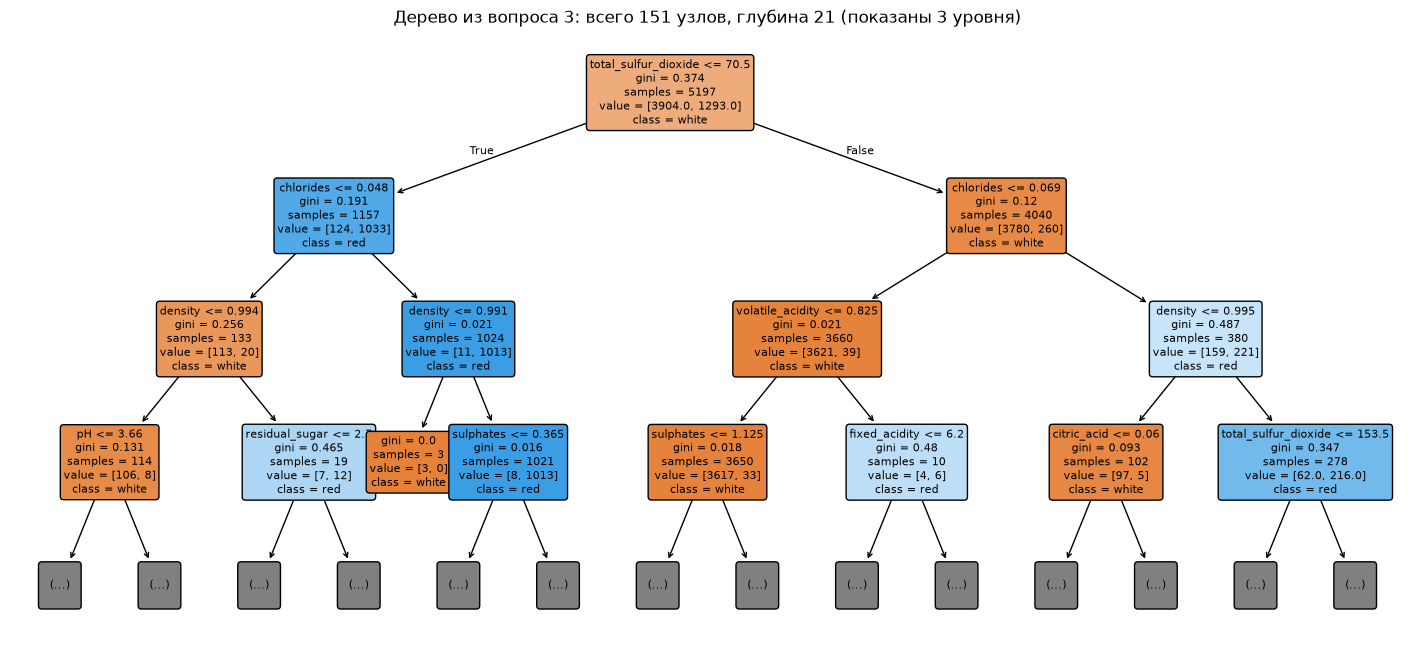

In [22]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(dt, max_depth=3, feature_names=feature_cols, class_names=['white', 'red'],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f'Дерево из вопроса 3: всего {dt.tree_.node_count} узлов, глубина {dt.get_depth()} (показаны 3 уровня)');

Дерево, построенное с помощью перекрёстной валидации в вопросе 4. Это дерево намного менее глубокое, чем предыдущее, и показано полностью.

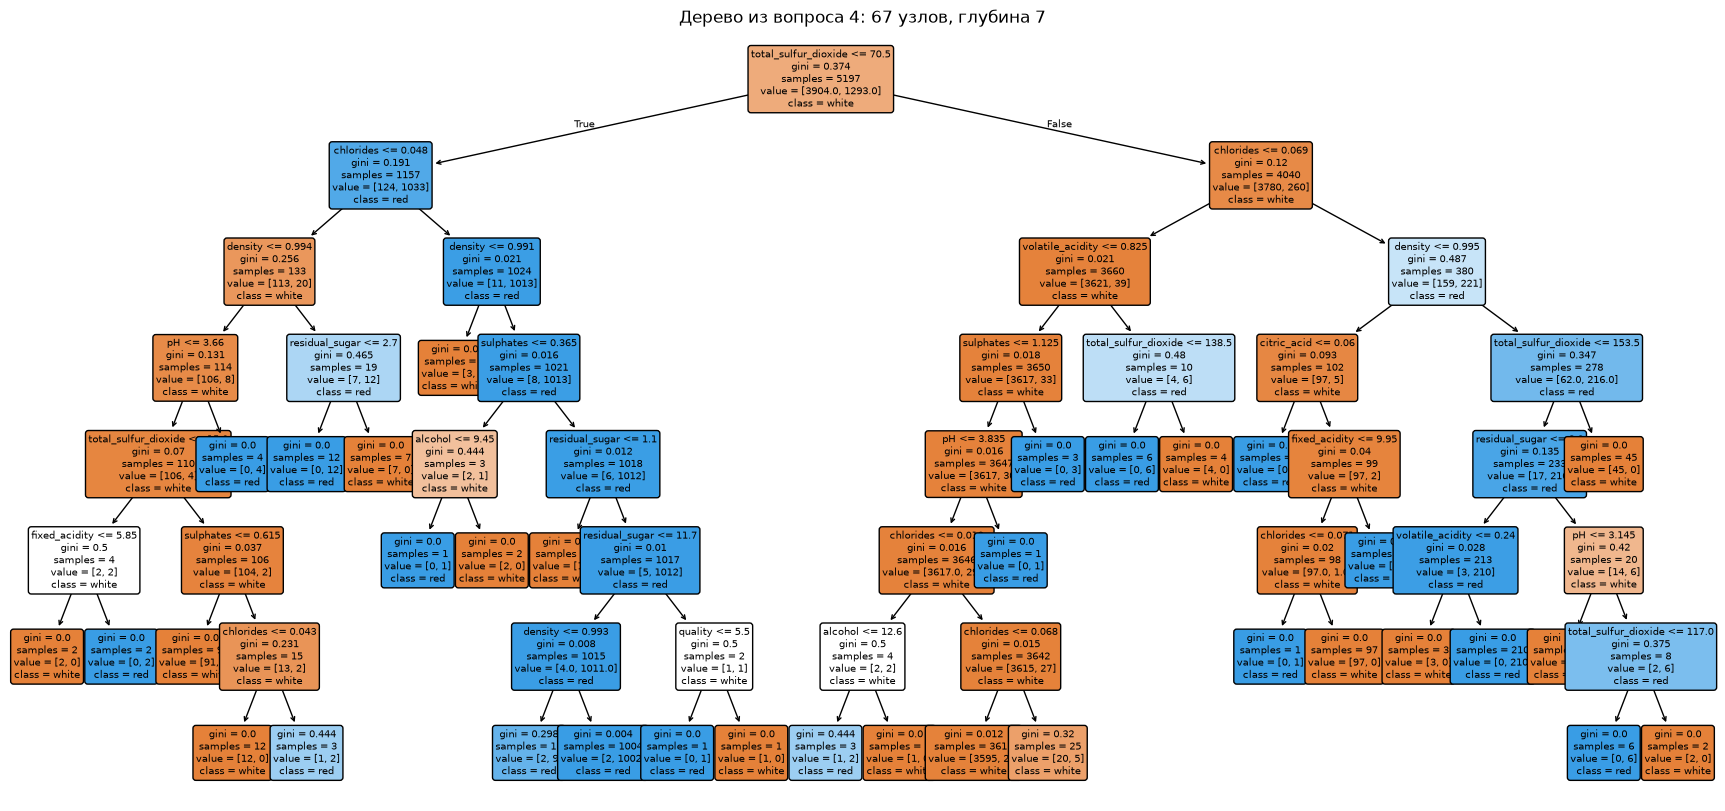

In [23]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(dt_cv, feature_names=feature_cols, class_names=['white', 'red'],
          filled=True, rounded=True, fontsize=7, ax=ax)
ax.set_title(f'Дерево из вопроса 4: {dt_cv.tree_.node_count} узлов, глубина {dt_cv.get_depth()}');

### Выводы к вопросу 6

* GraphViz и PyDotPlus в окружении не установлены, поэтому визуализация выполнена средствами `sklearn.tree.plot_tree`; это даёт то же содержание: в каждом узле указаны условие разбиения, `gini`, число объектов, распределение классов `value` и преобладающий класс.
* **Корень обоих деревьев** — `total_sulfur_dioxide ≤ 70,5`: это самый информативный признак (совпадает с наибольшей корреляцией с цветом из лабораторной работы 7). Слева (мало SO₂) оказываются в основном красные вина (1 033 из 1 157), справа — белые (3 780 из 4 040). Следующие разбиения используют `chlorides`, `density`, `volatile_acidity`, `sulphates`.
* **Дерево из вопроса 3** слишком велико для полной отрисовки (151 узел), поэтому показаны только 3 верхних уровня: глубже расположены «узкоспециализированные» разбиения, выделяющие единичные объекты — это и есть признак переобучения. **Дерево из вопроса 4** (67 узлов, глубина 7) читается целиком, и по нему можно проследить правила классификации.
* Главное достоинство деревьев решений — **интерпретируемость**: решение объясняется цепочкой простых условий «признак ≤ порог». Основной недостаток — склонность к переобучению при отсутствии ограничений.

### Общие выводы

* **Принцип работы:** дерево решений рекурсивно делит выборку по признаку и порогу, которые лучше всего уменьшают неоднородность (индекс Джини для классификации, MSE для регрессии), пока не будет достигнут критерий остановки.
* **Классификация цвета вина** деревом решений даёт точность около 98,5 % на тесте; главный признак — общее содержание диоксида серы.
* **Переобучение:** дерево без ограничений даёт почти идеальное качество на обучении (0,9996) и заметно хуже на тесте; ограничение `max_depth` (подбор через `GridSearchCV`) уменьшило дерево в 2 раза (151 → 67 узлов) при той же тестовой точности.
* **Регрессия:** дерево предсказывает остаточный сахар с RMSE ≈ 1,8 г/л (R² ≈ 0,86), но переобучается сильнее, чем классификатор, из-за непрерывной цели и большого числа листьев.
* **Сильные стороны:** интерпретируемость, отсутствие необходимости масштабировать данные, работа и с классификацией, и с регрессией. **Слабые стороны:** склонность к переобучению, неустойчивость к небольшим изменениям данных, кусочно-постоянные предсказания.